In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import metpy.calc as mpcalc
from metpy.units import units
import cartopy.feature as cfeature
import numpy as np
from matplotlib.widgets import Slider, Button

In [3]:
center_lat = 19.26626706
center_lon = 119.72428415

In [4]:
eraFile_upper = '../../data/era5/ERA5_upperAir_CAMP2Ex_RF17.nc'
era_data_upper = xr.open_dataset(eraFile_upper)
era_data_upper_sub = era_data_upper.isel(valid_time=1)

In [5]:
eraFile_surface = '../../data/era5/ERA5_surface_CAMP2Ex_RF17.nc'
era_data_surface = xr.open_dataset(eraFile_surface)
era_data_surface_sub = era_data_surface.isel(valid_time=1)

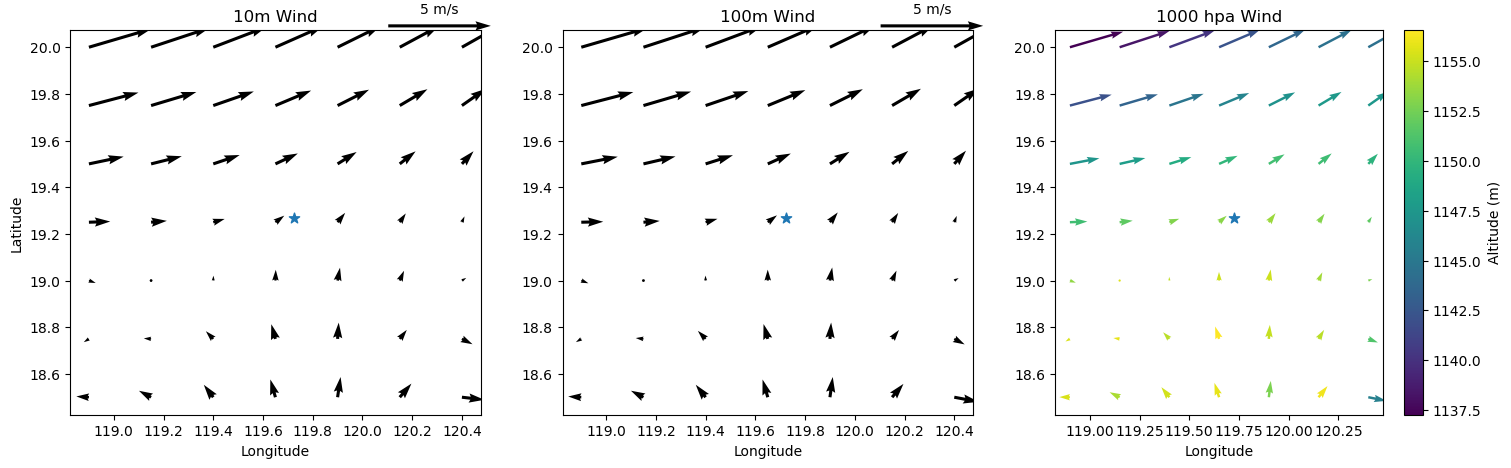

In [6]:
f, ax = plt.subplots(1, 3, figsize=(18, 5))
q0 = ax[0].quiver(era_data_surface_sub.longitude, era_data_surface_sub.latitude, era_data_surface_sub.u10, era_data_surface_sub.v10, scale=20)
ax[0].quiverkey(q0, 0.9, 1.01, 5, label='5 m/s', labelpos='N')
ax[0].set_title('10m Wind')
ax[0].set_xlabel('Longitude')
ax[0].set_ylabel('Latitude')
ax[0].scatter(center_lon, center_lat, marker='*', s=60)

q1 = ax[1].quiver(era_data_surface_sub.longitude, era_data_surface_sub.latitude, era_data_surface_sub.u100, era_data_surface_sub.v100, scale=20)
ax[1].quiverkey(q1, 0.9, 1.01, 5, label='5 m/s', labelpos='N')
ax[1].set_title('100m Wind')
ax[1].set_xlabel('Longitude')
ax[1].scatter(center_lon, center_lat, marker='*', s=60)

upper_tmp = era_data_upper_sub.isel(pressure_level=0).copy(deep=True)
q2 = ax[2].quiver(upper_tmp.longitude, upper_tmp.latitude, upper_tmp.u, upper_tmp.v, upper_tmp.z, scale=20)
ax[2].quiverkey(q2, 0.9, 1.01, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(q2, label='Altitude (m)')
ax[2].set_xlabel('Longitude')
ax[2].set_title('{:.0f} hpa Wind'.format(upper_tmp.pressure_level.data))
ax[2].scatter(center_lon, center_lat, marker='*', s=60)

# upper_tmp = era_data_upper_sub.isel(pressure_level=1).copy(deep=True)
# q3 = ax[3].quiver(upper_tmp.longitude, upper_tmp.latitude, upper_tmp.u, upper_tmp.v, upper_tmp.z)
# ax[3].quiverkey(q3, 0.0, 0.0, 5, '5 m/s', labelpos='N', coordinates='figure')
# # plt.colorbar(q, label='Altitude (m)')
# ax[3].set_xlabel('Longitude')
# ax[3].set_title('{:.0f} hpa Wind'.format(upper_tmp.pressure_level.data))

Text(0.5, 1.0, '1000 hpa Wind')

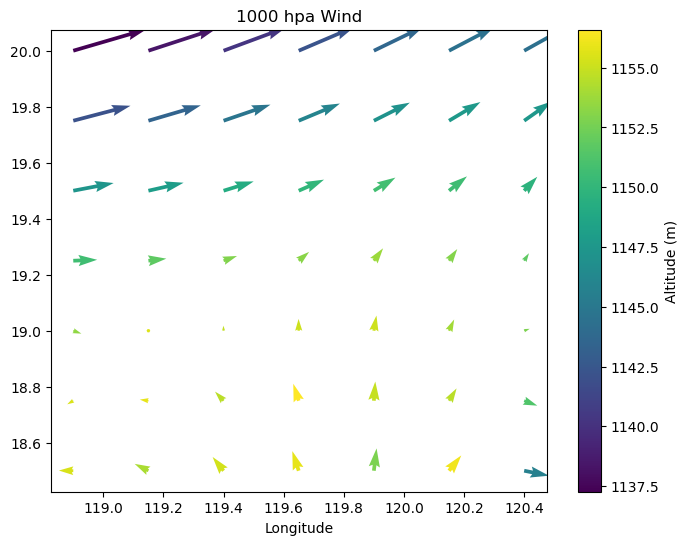

In [7]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
upper_tmp = era_data_upper_sub.isel(pressure_level=0).copy(deep=True)
q3 = ax.quiver(upper_tmp.longitude, upper_tmp.latitude, upper_tmp.u, upper_tmp.v, upper_tmp.z)
plt.colorbar(q3, label='Altitude (m)')
ax.quiverkey(q3, 0.0, 0.0, 5, '5 m/s', labelpos='N', coordinates='figure')
ax.set_xlabel('Longitude')
ax.set_title('{:.0f} hpa Wind'.format(upper_tmp.pressure_level.data))

In [15]:
surface_center = era_data_surface.sel(latitude=center_lat, longitude=center_lon, method='nearest').isel(valid_time=1).copy(deep=True)
print('10m Velocity East: {:.3f} m/s'.format(surface_center.u10.data))
print('10m Velocity North: {:.3f} m/s'.format(surface_center.v10.data))
print('10m Wind Speed: {:.3f} m/s'.format((surface_center.u10.data**2 + surface_center.v10.data**2)**0.5))
print()
print('100m Velocity East: {:.3f} m/s'.format(surface_center.u100.data))
print('100m Velocity North: {:.3f} m/s'.format(surface_center.v100.data))
print('100m Wind Speed: {:.3f} m/s'.format((surface_center.u100.data**2 + surface_center.v100.data**2)**0.5))

upper_center = era_data_upper.sel(latitude=center_lat, longitude=center_lon, method='nearest').isel(valid_time=1).copy(deep=True)
for i in range(2):
    print()
    print('{:.0f}m Velocity East: {:.3f} m/s'.format(upper_center.z[i].data, upper_center.u[i].data))
    print('{:.0f}m Velocity North: {:.3f} m/s'.format(upper_center.z[i].data, upper_center.v[i].data))
    print('{:.0f}m Wind Speed: {:.3f} m/s'.format(upper_center.z[i].data, (upper_center.u[i].data**2 + upper_center.v[i].data**2)**0.5))

10m Velocity East: 0.432 m/s
10m Velocity North: 0.321 m/s
10m Wind Speed: 0.538 m/s

100m Velocity East: 0.449 m/s
100m Velocity North: 0.336 m/s
100m Wind Speed: 0.561 m/s

1153m Velocity East: 0.462 m/s
1153m Velocity North: 0.394 m/s
1153m Wind Speed: 0.607 m/s

3350m Velocity East: 0.440 m/s
3350m Velocity North: 0.406 m/s
3350m Wind Speed: 0.599 m/s
